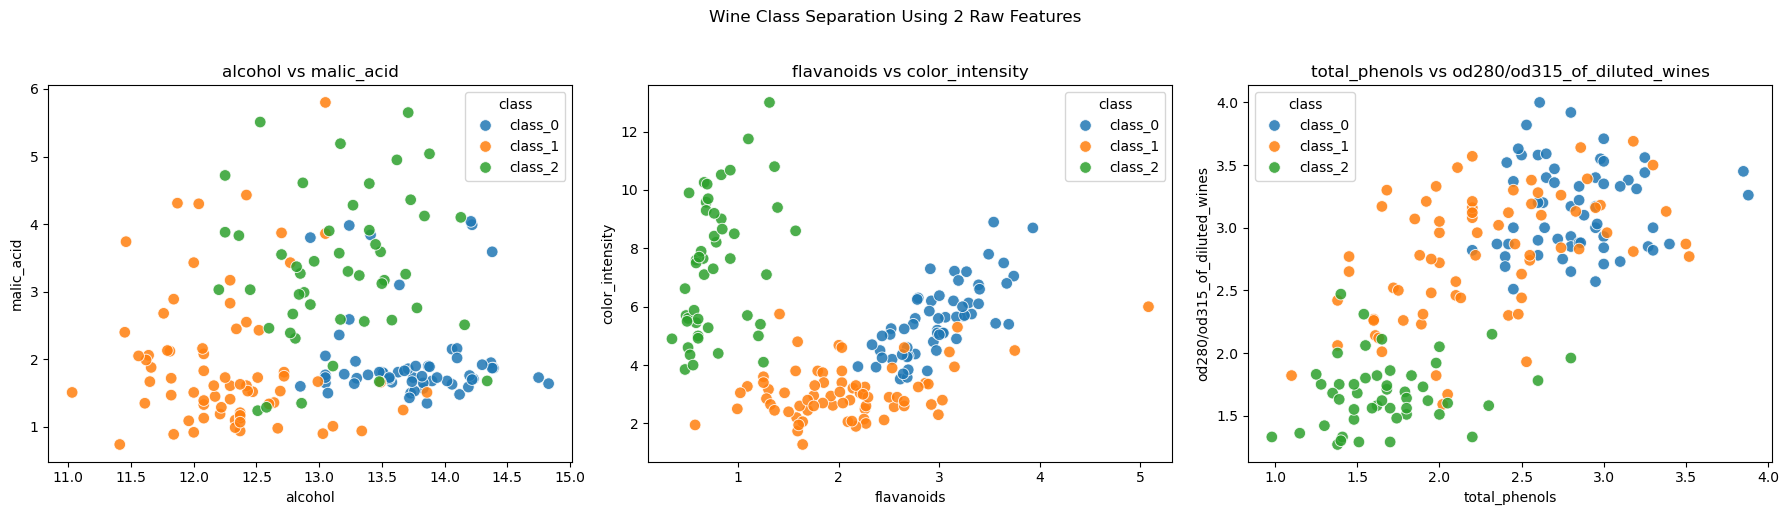

C:\Users\VICTUS\anaconda3\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


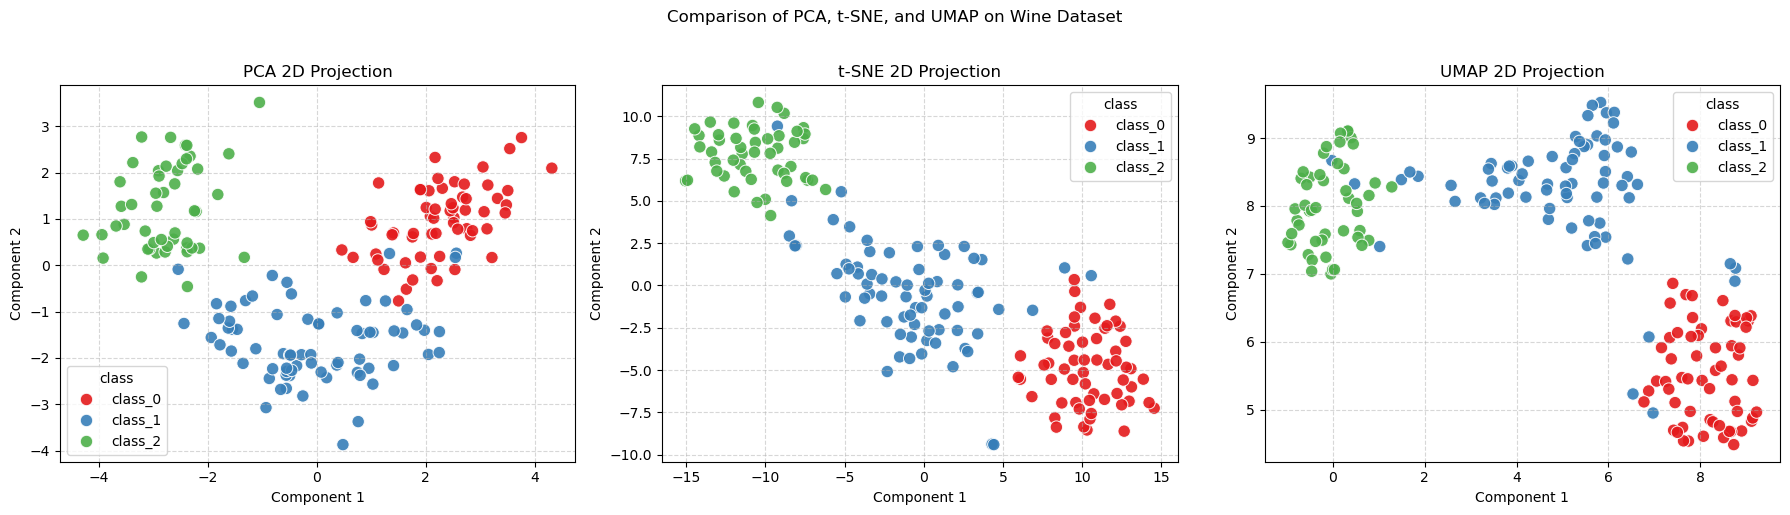

C:\Users\VICTUS\anaconda3\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


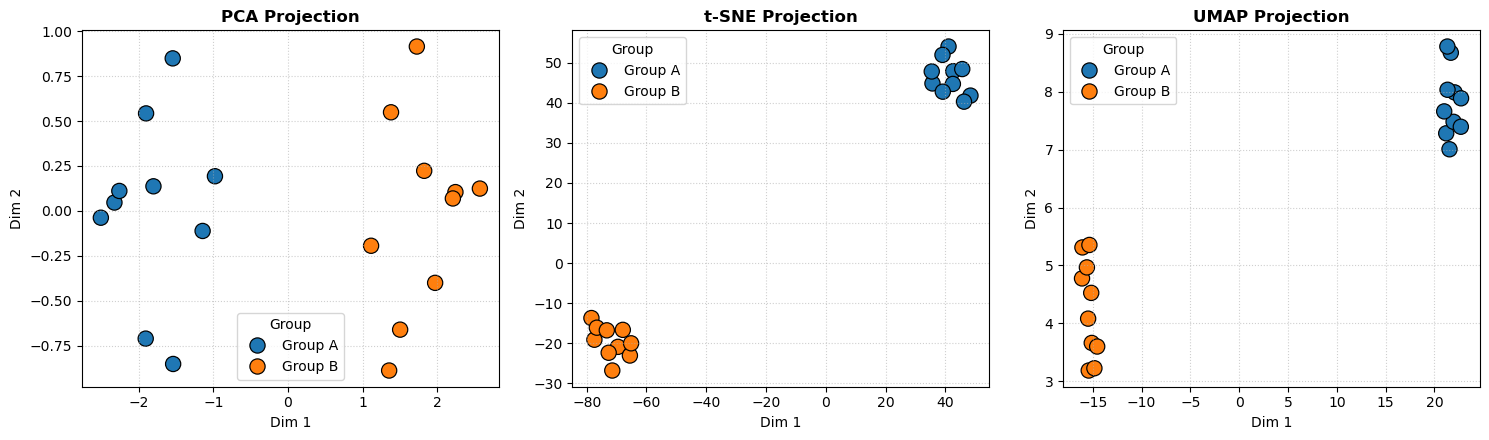

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from umap import UMAP

# ==========================================
# PART 1: WINE DATASET DIMENSIONALITY REDUCTION
# ==========================================

# 1. Load dataset & inspect features
wine = load_wine()
X = wine.data
y = wine.target
feature_names = wine.feature_names
target_names = wine.target_names
df_wine = pd.DataFrame(X, columns=feature_names)
df_wine["class"] = [target_names[i] for i in y]

# 2. 2-feature Pairwise Evaluation (3 pairs)
pairs = [
    ("alcohol", "malic_acid"),
    ("flavanoids", "color_intensity"),
    ("total_phenols", "od280/od315_of_diluted_wines"),
]

fig1, axes1 = plt.subplots(1, 3, figsize=(18, 5))
for ax, (f1, f2) in zip(axes1, pairs):
    sns.scatterplot(
        data=df_wine, x=f1, y=f2, hue="class", palette="tab10", s=70, ax=ax, alpha=0.85
    )
    ax.set_title(f"{f1} vs {f2}")
plt.suptitle("Wine Class Separation Using 2 Raw Features", y=1.02)
plt.tight_layout()
plt.show()

# 3. Standardization
scaler = StandardScaler()
X_scaled_wine = scaler.fit_transform(X)

# 4. Dimensionality Reduction to 2D
X_pca_wine = PCA(n_components=2, random_state=42).fit_transform(X_scaled_wine)
X_tsne_wine = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(X_scaled_wine)
X_umap_wine = UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=42).fit_transform(X_scaled_wine)

# 5. Side-by-Side Comparison Plot
embeddings = [("PCA", X_pca_wine), ("t-SNE", X_tsne_wine), ("UMAP", X_umap_wine)]
fig2, axes2 = plt.subplots(1, 3, figsize=(18, 5))

for ax, (method, emb) in zip(axes2, embeddings):
    plot_df = pd.DataFrame(emb, columns=["Component 1", "Component 2"])
    plot_df["class"] = df_wine["class"]
    sns.scatterplot(
        data=plot_df, x="Component 1", y="Component 2", hue="class", palette="Set1", s=80, ax=ax, alpha=0.9
    )
    ax.set_title(f"{method} 2D Projection")
    ax.grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Comparison of PCA, t-SNE, and UMAP on Wine Dataset", y=1.02)
plt.tight_layout()
plt.show()


# ==========================================
# PART 2: OUTPUT-DRIVEN PROBLEM SOLVING (BUG FIXES)
# ==========================================

# --- DATASET GENERATION (Preserved) ---
np.random.seed(42)
data = np.random.randn(20, 4)
data[10:, :] += 3.5  # Create 2 groups
labels = ['Group A'] * 10 + ['Group B'] * 10
df_synth = pd.DataFrame(data, columns=['F1', 'F2', 'F3', 'F4'])

# Fix 1: Apply StandardScaler to the feature values
X_scaled_synth = scaler.fit_transform(df_synth)

# Fix 2: Adjust t-SNE perplexity to be strictly less than n_samples (n=20)
pca_res = PCA(n_components=2, random_state=42).fit_transform(X_scaled_synth)
tsne_res = TSNE(n_components=2, perplexity=5, random_state=42).fit_transform(X_scaled_synth)
umap_res = UMAP(n_components=2, n_neighbors=5, random_state=42).fit_transform(X_scaled_synth)

# Fix 3: Include group labels in DataFrame and assign hue
fig3, axes3 = plt.subplots(1, 3, figsize=(15, 4.5))
results = [('PCA', pca_res), ('t-SNE', tsne_res), ('UMAP', umap_res)]

for ax, (title, res_data) in zip(axes3, results):
    plot_df = pd.DataFrame(res_data, columns=['Dim 1', 'Dim 2'])
    plot_df['Group'] = labels
    
    sns.scatterplot(
        data=plot_df, x='Dim 1', y='Dim 2', hue='Group', 
        palette={'Group A': '#1f77b4', 'Group B': '#ff7f0e'}, s=120, ax=ax, edgecolor='k'
    )
    ax.set_title(f"{title} Projection", fontsize=12, fontweight='bold')
    ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()